In [1]:

from google.colab import files

uploaded = files.upload()


Saving full_grouped.csv to full_grouped.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [8]:

df = pd.read_csv('full_grouped.csv')

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [4]:

df.head()


,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa
3,2020-01-22,Andorra,0,0,0,0,0,0,0,Europe
4,2020-01-22,Angola,0,0,0,0,0,0,0,Africa


In [5]:

print("Rows and Columns:", df.shape)


Rows and Columns: (35156, 10)


In [6]:

print("Column Names:")
print(df.columns.tolist())


Column Names:
['Date', 'Country/Region', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'New cases', 'New deaths', 'New recovered', 'WHO Region']


In [7]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35156 entries, 0 to 35155
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            35156 non-null  object
 1   Country/Region  35156 non-null  object
 2   Confirmed       35156 non-null  int64 
 3   Deaths          35156 non-null  int64 
 4   Recovered       35156 non-null  int64 
 5   Active          35156 non-null  int64 
 6   New cases       35156 non-null  int64 
 7   New deaths      35156 non-null  int64 
 8   New recovered   35156 non-null  int64 
 9   WHO Region      35156 non-null  object
dtypes: int64(7), object(3)
memory usage: 2.7+ MB


In [9]:

print("Missing Values in Each Column:")
print(df.isnull().sum())


Missing Values in Each Column:
Date              0
Country/Region    0
Confirmed         0
Deaths            0
Recovered         0
Active            0
New cases         0
New deaths        0
New recovered     0
WHO Region        0
dtype: int64


In [10]:

print("Duplicate Records:", df.duplicated().sum())


Duplicate Records: 0


In [11]:

df = df.drop_duplicates()

print("Duplicate records removed!")
print("Updated Shape:", df.shape)


Duplicate records removed!
Updated Shape: (35156, 10)


In [12]:

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = df[numeric_columns].fillna(0)

print("Missing numerical values handled!")


Missing numerical values handled!


In [13]:

df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

print("Date column converted successfully!")
print(df['Date'].head())


Date column converted successfully!
0   2020-01-22
1   2020-01-22
2   2020-01-22
3   2020-01-22
4   2020-01-22
Name: Date, dtype: datetime64[ns]


In [14]:

print("Final Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)


Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35156 entries, 0 to 35155
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            35156 non-null  datetime64[ns]
 1   Country/Region  35156 non-null  object        
 2   Confirmed       35156 non-null  int64         
 3   Deaths          35156 non-null  int64         
 4   Recovered       35156 non-null  int64         
 5   Active          35156 non-null  int64         
 6   New cases       35156 non-null  int64         
 7   New deaths      35156 non-null  int64         
 8   New recovered   35156 non-null  int64         
 9   WHO Region      35156 non-null  object        
dtypes: datetime64[ns](1), int64(7), object(2)
memory usage: 2.7+ MB
None

Missing Values:
Date              0
Country/Region    0
Confirmed         0
Deaths            0
Recovered         0
Active            0
New cases         0
New death

In [15]:

df.to_csv('COVID19_Cleaned_Data.csv', index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [16]:

from google.colab import files

files.download('COVID19_Cleaned_Data.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

total_cases = df['Confirmed'].sum()

print("Total Confirmed Cases:", total_cases)


Total Confirmed Cases: 828508482


In [18]:

total_deaths = df['Deaths'].sum()

print("Total Deaths:", total_deaths)


Total Deaths: 43384903


In [19]:

total_recovered = df['Recovered'].sum()

print("Total Recovered Cases:", total_recovered)


Total Recovered Cases: 388408229


In [20]:

country_cases = df.groupby('Country/Region')['Confirmed'].sum()

top_countries = country_cases.sort_values(
    ascending=False
).head(10)

print(top_countries)


Country/Region
US                224345948
Brazil             89524967
Russia             45408411
India              40883464
Spain              27404045
United Kingdom     26748587
Italy              26745145
France             21210926
Germany            21059152
Iran               19339267
Name: Confirmed, dtype: int64


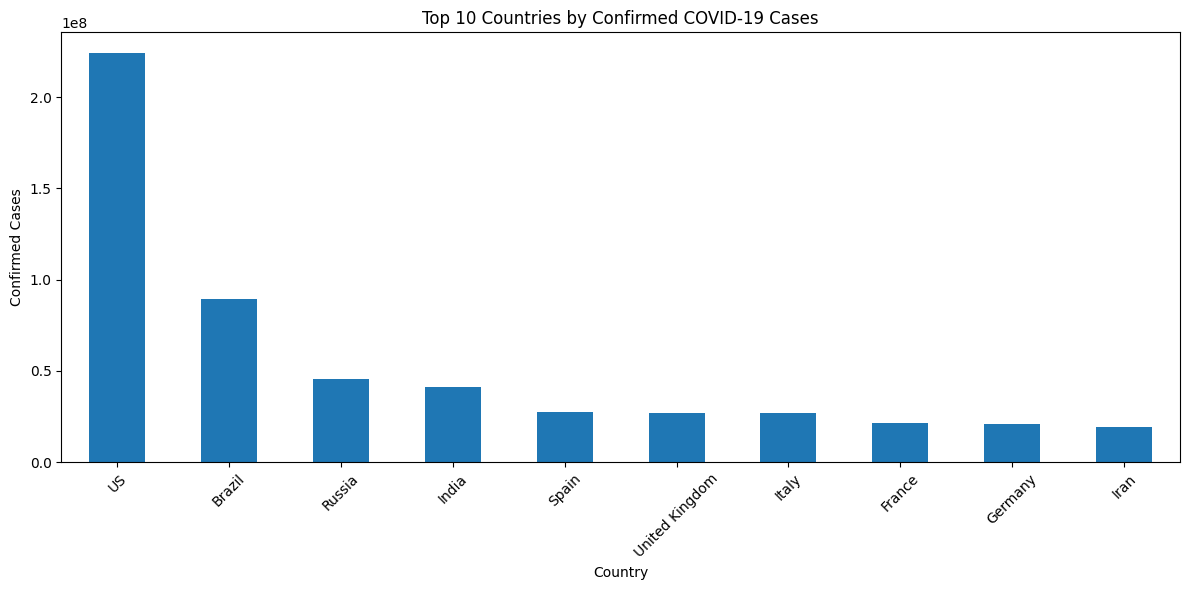

In [21]:

plt.figure(figsize=(12,6))

top_countries.plot(kind='bar')

plt.title('Top 10 Countries by Confirmed COVID-19 Cases')
plt.xlabel('Country')
plt.ylabel('Confirmed Cases')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


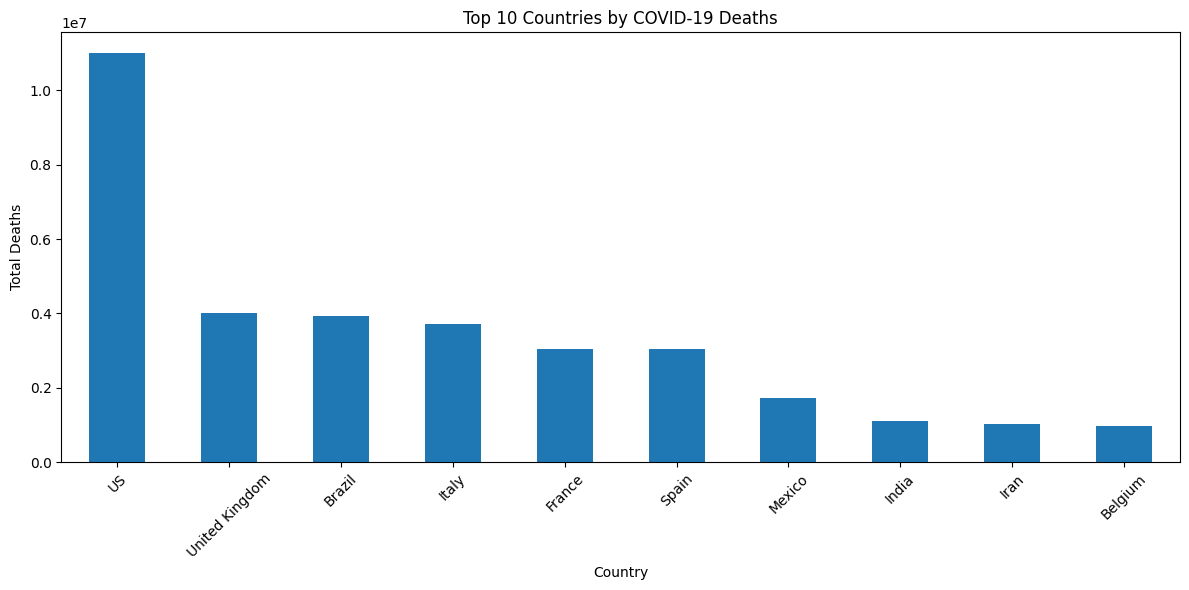

In [22]:

country_deaths = df.groupby('Country/Region')['Deaths'].sum()

top_deaths = country_deaths.sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12,6))

top_deaths.plot(kind='bar')

plt.title('Top 10 Countries by COVID-19 Deaths')
plt.xlabel('Country')
plt.ylabel('Total Deaths')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


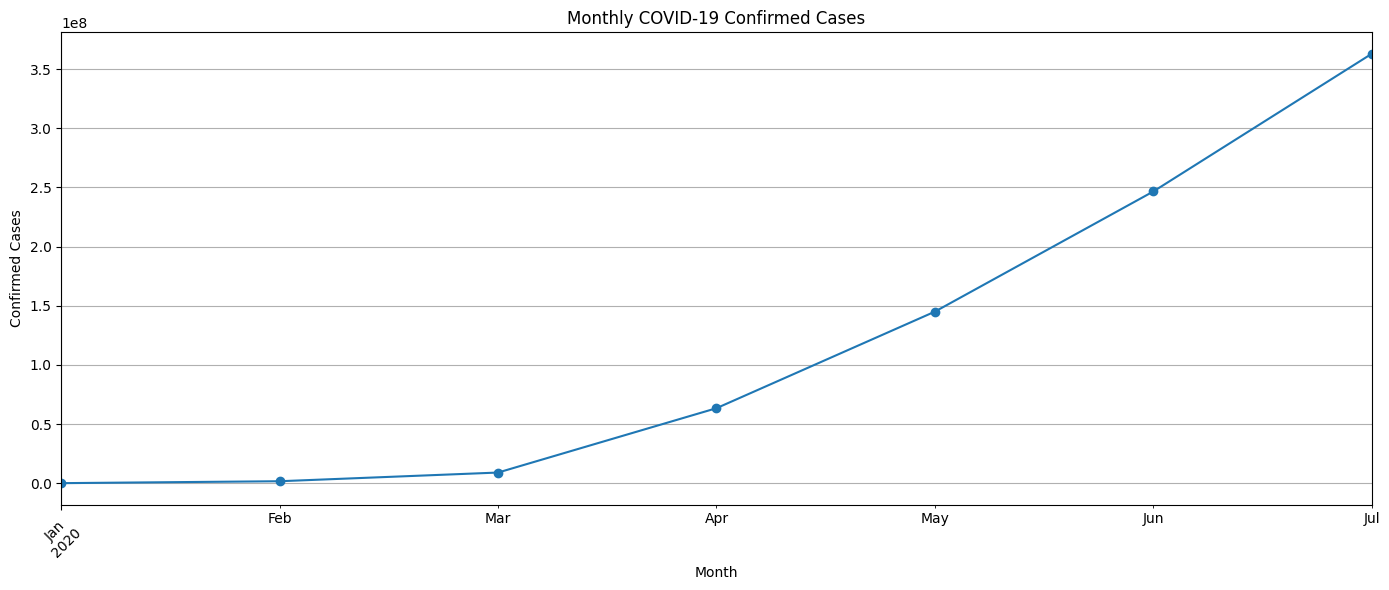

In [23]:

df['Month'] = df['Date'].dt.to_period('M')

monthly_cases = df.groupby('Month')['Confirmed'].sum()

plt.figure(figsize=(14,6))

monthly_cases.plot(kind='line', marker='o')

plt.title('Monthly COVID-19 Confirmed Cases')
plt.xlabel('Month')
plt.ylabel('Confirmed Cases')

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()


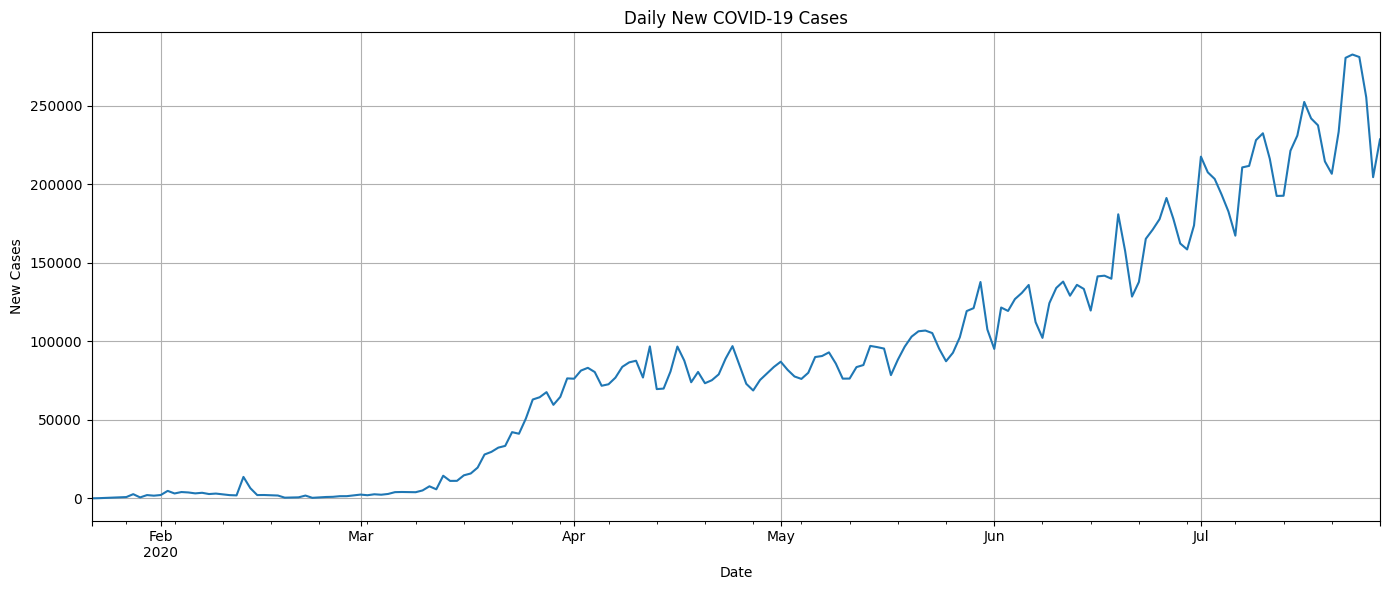

In [24]:

daily_cases = df.groupby('Date')['New cases'].sum()

plt.figure(figsize=(14,6))

daily_cases.plot()

plt.title('Daily New COVID-19 Cases')
plt.xlabel('Date')
plt.ylabel('New Cases')

plt.grid()
plt.tight_layout()
plt.show()


In [25]:

country_summary = df.groupby('Country/Region').agg({
    'Confirmed': 'max',
    'Deaths': 'max',
    'Recovered': 'max',
    'Active': 'max'
}).reset_index()

country_summary.to_csv(
    'COVID19_Country_Analysis.csv',
    index=False
)

print("Country analysis exported successfully!")


Country analysis exported successfully!


In [26]:

country_summary = df.groupby('Country/Region').agg({
    'Confirmed': 'max',
    'Deaths': 'max',
    'Recovered': 'max',
    'Active': 'max'
}).reset_index()

country_summary = country_summary.sort_values(
    by='Confirmed',
    ascending=False
)

country_summary.head(10)


,Country/Region,Confirmed,Deaths,Recovered,Active
173,US,4290259,148011,1325804,2816444
23,Brazil,2442375,87618,1846641,583080
79,India,1480073,33408,951166,495499
138,Russia,816680,13334,602249,245382
154,South Africa,452529,7067,274925,173590
111,Mexico,395489,44022,303810,53572
132,Peru,389717,18418,272547,108616
35,Chile,347923,9187,319954,82961
177,United Kingdom,301708,45844,1437,254427
81,Iran,293606,15912,255144,34887


In [27]:

top_5 = country_summary.head(5)

print("Top 5 Countries by Confirmed Cases")
print(top_5[['Country/Region', 'Confirmed']])


Top 5 Countries by Confirmed Cases
    Country/Region  Confirmed
173             US    4290259
23          Brazil    2442375
79           India    1480073
138         Russia     816680
154   South Africa     452529


In [28]:

total_confirmed = df['Confirmed'].sum()
total_deaths = df['Deaths'].sum()
total_recovered = df['Recovered'].sum()

print("Recovery Rate:",
      round(total_recovered / total_confirmed * 100, 2), "%")

print("Case Fatality Rate:",
      round(total_deaths / total_confirmed * 100, 2), "%")


Recovery Rate: 46.88 %
Case Fatality Rate: 5.24 %


In [30]:

latest_date = df['Date'].max()

latest_data = df[df['Date'] == latest_date]

total_confirmed = latest_data['Confirmed'].sum()
total_deaths = latest_data['Deaths'].sum()
total_recovered = latest_data['Recovered'].sum()

recovery_rate = total_recovered / total_confirmed * 100
fatality_rate = total_deaths / total_confirmed * 100

print("Latest Date:", latest_date)
print("Global Confirmed:", total_confirmed)
print("Global Deaths:", total_deaths)
print("Global Recovered:", total_recovered)
print("Recovery Rate:", round(recovery_rate, 2), "%")
print("Case Fatality Rate:", round(fatality_rate, 2), "%")


Latest Date: 2020-07-27 00:00:00
Global Confirmed: 16480485
Global Deaths: 654036
Global Recovered: 9468087
Recovery Rate: 57.45 %
Case Fatality Rate: 3.97 %
